In [2]:

%pip install pandas numpy scikit-learn matplotlib seaborn torch joblib


   ---------------------------------------- 0.0/124.1 MB ? eta -:--:--
   ---------------------------------------- 1.3/124.1 MB 9.0 MB/s eta 0:00:14
   - -------------------------------------- 3.1/124.1 MB 8.6 MB/s eta 0:00:15
   - -------------------------------------- 5.0/124.1 MB 8.7 MB/s eta 0:00:14
   -- ------------------------------------- 6.6/124.1 MB 8.4 MB/s eta 0:00:15
   -- ------------------------------------- 8.1/124.1 MB 8.2 MB/s eta 0:00:15
   --- ------------------------------------ 9.7/124.1 MB 8.1 MB/s eta 0:00:15
   --- ------------------------------------ 11.3/124.1 MB 8.0 MB/s eta 0:00:15
   ---- ----------------------------------- 13.1/124.1 MB 8.2 MB/s eta 0:00:14
   ---- ----------------------------------- 14.4/124.1 MB 7.9 MB/s eta 0:00:14
   ----- ---------------------------------- 15.7/124.1 MB 7.7 MB/s eta 0:00:15
   ----- ---------------------------------- 17.0/124.1 MB 7.6 MB/s eta 0:00:15
   ----- ---------------------------------- 18.6/124.1 MB 7.6 MB/s

In [6]:

import pandas as pd
import numpy as np
import urllib.request
import zipfile
from pathlib import Path

# Separate folder for the NLP dataset
DATA_DIR = Path("data/sms_spam_collection")
DATA_DIR.mkdir(parents=True, exist_ok=True)

zip_path = DATA_DIR / "sms_spam_collection.zip"
file_path = DATA_DIR / "SMSSpamCollection"

url = (
    "https://archive.ics.uci.edu/static/public/228/"
    "sms+spam+collection.zip"
)

# Download only if the dataset file is missing
if not file_path.exists():
    urllib.request.urlretrieve(url, zip_path)

    with zipfile.ZipFile(zip_path, "r") as z:
        z.extractall(DATA_DIR)

# Load the correct NLP dataset
df = pd.read_csv(
    file_path,
    sep="\t",
    header=None,
    names=["label", "message"],
    encoding="utf-8"
)

# Convert labels: ham = 0, spam = 1
df["label"] = df["label"].map({"ham": 0, "spam": 1})

df = df.dropna(subset=["label", "message"])
df["label"] = df["label"].astype(int)
df = df.drop_duplicates(subset=["message"]).reset_index(drop=True)

print("Dataset shape:", df.shape)
print("\nColumns:", df.columns.tolist())
print("\nClass distribution:")
print(df["label"].value_counts().rename(
    index={0: "Not Spam", 1: "Spam"}
))
display(df.head())


Dataset shape: (5169, 2)

Columns: ['label', 'message']

Class distribution:
label
Not Spam    4516
Spam         653
Name: count, dtype: int64


,label,message
0,0,"Go until jurong point, crazy.. Available only ..."
1,0,Ok lar... Joking wif u oni...
2,1,Free entry in 2 a wkly comp to win FA Cup fina...
3,0,U dun say so early hor... U c already then say...
4,0,"Nah I don't think he goes to usf, he lives aro..."


In [4]:

# Cell 3: Locate and load the existing churn dataset

possible_paths = [
    Path.cwd() / "data" / "customer-churn-training.csv",
    Path.cwd().parent / "data" / "customer-churn-training.csv",
    Path.cwd() / "customer-churn-training.csv"
]

DATA_PATH = next(
    (path for path in possible_paths if path.exists()),
    None
)

if DATA_PATH is None:
    raise FileNotFoundError(
        "Dataset not found. Check the location of "
        "'data/customer-churn-training.csv'."
    )

df = pd.read_csv(DATA_PATH)

print("Dataset path:", DATA_PATH.resolve())
print("Dataset shape:", df.shape)
print("\nColumns:", df.columns.tolist())
print("\nFirst five rows:")
display(df.head())

print("\nMissing values:")
display(df.isnull().sum())

print("\nTarget distribution:")
display(df["churned"].value_counts().sort_index())


Dataset path: D:\INTERNSHIP WORK\RabTech-AI-ML-Internship\data\customer-churn-training.csv
Dataset shape: (12, 7)

Columns: ['customer_id', 'tenure_months', 'support_tickets', 'monthly_spend_inr', 'last_login_days', 'plan_type', 'churned']

First five rows:


,customer_id,tenure_months,support_tickets,monthly_spend_inr,last_login_days,plan_type,churned
0,C001,2,4,499,21,Basic,1
1,C002,18,1,1299,2,Pro,0
2,C003,6,3,799,14,Basic,1
3,C004,30,0,1499,1,Pro,0
4,C005,11,2,999,5,Standard,0



Missing values:


customer_id          0
tenure_months        0
support_tickets      0
monthly_spend_inr    0
last_login_days      0
plan_type            0
churned              0
dtype: int64


Target distribution:


churned
0    7
1    5
Name: count, dtype: int64

In [7]:

import pandas as pd
import urllib.request
import zipfile
from pathlib import Path

data_dir = Path("data/sms_spam_collection")
data_dir.mkdir(parents=True, exist_ok=True)

zip_path = data_dir / "sms_spam_collection.zip"
csv_path = data_dir / "SMSSpamCollection"

url = "https://archive.ics.uci.edu/static/public/228/sms+spam+collection.zip"

if not csv_path.exists():
    urllib.request.urlretrieve(url, zip_path)
    with zipfile.ZipFile(zip_path, "r") as archive:
        archive.extractall(data_dir)

df = pd.read_csv(
    csv_path,
    sep="\t",
    header=None,
    names=["label", "message"],
    encoding="utf-8"
)

df["label"] = df["label"].map({"ham": 0, "spam": 1})
df = df.dropna(subset=["label", "message"])
df["label"] = df["label"].astype(int)
df = df.drop_duplicates(subset=["message"]).reset_index(drop=True)

print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())
display(df.head())


Dataset shape: (5169, 2)
Columns: ['label', 'message']


,label,message
0,0,"Go until jurong point, crazy.. Available only ..."
1,0,Ok lar... Joking wif u oni...
2,1,Free entry in 2 a wkly comp to win FA Cup fina...
3,0,U dun say so early hor... U c already then say...
4,0,"Nah I don't think he goes to usf, he lives aro..."


Dataset shape: (5169, 2)

Column names: ['label', 'message']

Missing values:
label      0
message    0
dtype: int64

Class distribution:
label
Not Spam    4516
Spam         653
Name: count, dtype: int64

Duplicate messages: 0


,label,message,message_length
0,0,"Go until jurong point, crazy.. Available only ...",111
1,0,Ok lar... Joking wif u oni...,29
2,1,Free entry in 2 a wkly comp to win FA Cup fina...,155
3,0,U dun say so early hor... U c already then say...,49
4,0,"Nah I don't think he goes to usf, he lives aro...",61


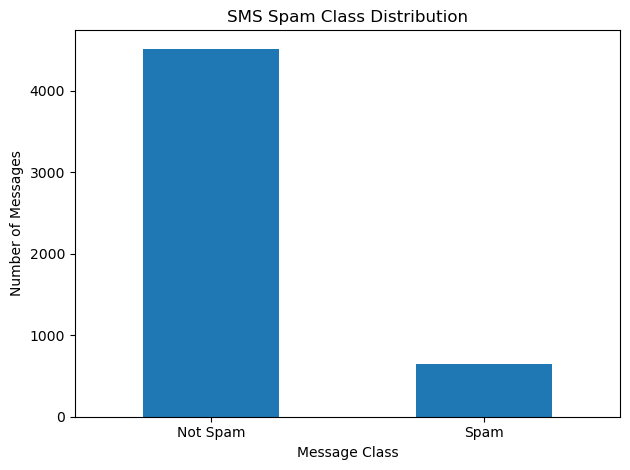

In [8]:

# STEP 3A: Dataset exploration

print("Dataset shape:", df.shape)
print("\nColumn names:", df.columns.tolist())

print("\nMissing values:")
print(df.isnull().sum())

print("\nClass distribution:")
print(
    df["label"]
    .value_counts()
    .rename(index={0: "Not Spam", 1: "Spam"})
)

print("\nDuplicate messages:", df["message"].duplicated().sum())

# Message length
df["message_length"] = df["message"].str.len()

display(df[["label", "message", "message_length"]].head())

# Visualize class distribution
df["label"].map({0: "Not Spam", 1: "Spam"}).value_counts().plot(
    kind="bar", rot=0
)
plt.title("SMS Spam Class Distribution")
plt.xlabel("Message Class")
plt.ylabel("Number of Messages")
plt.tight_layout()
plt.show()


In [9]:

# STEP 3B: Train / Validation / Test split

from sklearn.model_selection import train_test_split

X = df["message"].astype(str)
y = df["label"].astype(int)

X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    stratify=y,
    random_state=42
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    stratify=y_temp,
    random_state=42
)

print("Training samples:", len(X_train))
print("Validation samples:", len(X_val))
print("Testing samples:", len(X_test))

print("\nTraining class distribution:")
print(y_train.value_counts())


Training samples: 3618
Validation samples: 775
Testing samples: 776

Training class distribution:
label
0    3161
1     457
Name: count, dtype: int64


In [10]:

# STEP 3C: TF-IDF vectorization

from sklearn.feature_extraction.text import TfidfVectorizer
import numpy as np

vectorizer = TfidfVectorizer(
    max_features=5000,
    ngram_range=(1, 2),
    lowercase=True,
    strip_accents="unicode",
    sublinear_tf=True,
    dtype=np.float32
)

# Fit on training data only to prevent data leakage
X_train_vec = vectorizer.fit_transform(X_train).toarray()
X_val_vec = vectorizer.transform(X_val).toarray()
X_test_vec = vectorizer.transform(X_test).toarray()

y_train_np = y_train.to_numpy(dtype=np.float32)
y_val_np = y_val.to_numpy(dtype=np.float32)
y_test_np = y_test.to_numpy(dtype=np.float32)

print("Training feature shape:", X_train_vec.shape)
print("Validation feature shape:", X_val_vec.shape)
print("Test feature shape:", X_test_vec.shape)
print("Vocabulary size:", len(vectorizer.vocabulary_))


Training feature shape: (3618, 5000)
Validation feature shape: (775, 5000)
Test feature shape: (776, 5000)
Vocabulary size: 5000


In [11]:

# STEP 4A: Convert NumPy arrays to PyTorch tensors

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Training device:", device)

X_train_tensor = torch.tensor(X_train_vec, dtype=torch.float32)
X_val_tensor = torch.tensor(X_val_vec, dtype=torch.float32)
X_test_tensor = torch.tensor(X_test_vec, dtype=torch.float32)

y_train_tensor = torch.tensor(y_train_np, dtype=torch.float32).view(-1, 1)
y_val_tensor = torch.tensor(y_val_np, dtype=torch.float32).view(-1, 1)
y_test_tensor = torch.tensor(y_test_np, dtype=torch.float32).view(-1, 1)

train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
val_dataset = TensorDataset(X_val_tensor, y_val_tensor)
test_dataset = TensorDataset(X_test_tensor, y_test_tensor)

train_loader = DataLoader(
    train_dataset,
    batch_size=64,
    shuffle=True,
    generator=torch.Generator().manual_seed(SEED)
)

val_loader = DataLoader(val_dataset, batch_size=128, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=128, shuffle=False)

print("Input features:", X_train_tensor.shape[1])
print("Training batches:", len(train_loader))


Training device: cpu
Input features: 5000
Training batches: 57


In [12]:

# STEP 4B: Multi-layer neural network

class SpamClassifier(nn.Module):
    def __init__(self, input_dim):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(input_dim, 256),
            nn.BatchNorm1d(256),
            nn.ReLU(),
            nn.Dropout(0.40),

            nn.Linear(256, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Dropout(0.30),

            nn.Linear(128, 64),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.Dropout(0.20),

            nn.Linear(64, 1)
        )

    def forward(self, x):
        return self.network(x)


model = SpamClassifier(
    input_dim=X_train_tensor.shape[1]
).to(device)

criterion = nn.BCEWithLogitsLoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001,
    weight_decay=1e-4
)

print(model)
print("\nModel parameters:", sum(p.numel() for p in model.parameters()))


SpamClassifier(
  (network): Sequential(
    (0): Linear(in_features=5000, out_features=256, bias=True)
    (1): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): Dropout(p=0.4, inplace=False)
    (4): Linear(in_features=256, out_features=128, bias=True)
    (5): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU()
    (7): Dropout(p=0.3, inplace=False)
    (8): Linear(in_features=128, out_features=64, bias=True)
    (9): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (10): ReLU()
    (11): Dropout(p=0.2, inplace=False)
    (12): Linear(in_features=64, out_features=1, bias=True)
  )
)

Model parameters: 1322369


In [13]:

# STEP 4C: Training loop with early stopping

import copy

EPOCHS = 50
PATIENCE = 7
best_val_loss = float("inf")
best_weights = copy.deepcopy(model.state_dict())
epochs_without_improvement = 0

history = {
    "train_loss": [],
    "val_loss": [],
    "train_accuracy": [],
    "val_accuracy": []
}


def evaluate_epoch(model, loader, loss_fn):
    model.eval()
    total_loss = 0.0
    total_correct = 0
    total_samples = 0

    with torch.no_grad():
        for xb, yb in loader:
            xb = xb.to(device)
            yb = yb.to(device)

            logits = model(xb)
            loss = loss_fn(logits, yb)

            batch_size = xb.size(0)
            total_loss += loss.item() * batch_size

            predictions = (torch.sigmoid(logits) >= 0.5).float()
            total_correct += (predictions == yb).sum().item()
            total_samples += batch_size

    return (
        total_loss / total_samples,
        total_correct / total_samples
    )


for epoch in range(EPOCHS):
    model.train()
    total_train_loss = 0.0
    total_train_correct = 0
    total_train_samples = 0

    for xb, yb in train_loader:
        xb = xb.to(device)
        yb = yb.to(device)

        optimizer.zero_grad()
        logits = model(xb)
        loss = criterion(logits, yb)
        loss.backward()
        optimizer.step()

        batch_size = xb.size(0)
        total_train_loss += loss.item() * batch_size

        predictions = (torch.sigmoid(logits) >= 0.5).float()
        total_train_correct += (predictions == yb).sum().item()
        total_train_samples += batch_size

    train_loss = total_train_loss / total_train_samples
    train_accuracy = total_train_correct / total_train_samples

    val_loss, val_accuracy = evaluate_epoch(
        model, val_loader, criterion
    )

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["train_accuracy"].append(train_accuracy)
    history["val_accuracy"].append(val_accuracy)

    if val_loss < best_val_loss - 1e-4:
        best_val_loss = val_loss
        best_weights = copy.deepcopy(model.state_dict())
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1

    print(
        f"Epoch {epoch + 1:02d}/{EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Train Acc: {train_accuracy:.3f} | "
        f"Val Acc: {val_accuracy:.3f}"
    )

    if epochs_without_improvement >= PATIENCE:
        print(f"\nEarly stopping at epoch {epoch + 1}.")
        break

# Restore the best validation-loss model
model.load_state_dict(best_weights)
print("\nBest validation loss:", round(best_val_loss, 4))


Epoch 01/50 | Train Loss: 0.3622 | Val Loss: 0.2718 | Train Acc: 0.911 | Val Acc: 0.925
Epoch 02/50 | Train Loss: 0.1221 | Val Loss: 0.1014 | Train Acc: 0.993 | Val Acc: 0.981
Epoch 03/50 | Train Loss: 0.0595 | Val Loss: 0.0739 | Train Acc: 0.997 | Val Acc: 0.981
Epoch 04/50 | Train Loss: 0.0403 | Val Loss: 0.0701 | Train Acc: 0.996 | Val Acc: 0.983
Epoch 05/50 | Train Loss: 0.0270 | Val Loss: 0.0649 | Train Acc: 0.998 | Val Acc: 0.985
Epoch 06/50 | Train Loss: 0.0186 | Val Loss: 0.0670 | Train Acc: 0.998 | Val Acc: 0.981
Epoch 07/50 | Train Loss: 0.0152 | Val Loss: 0.0710 | Train Acc: 0.998 | Val Acc: 0.982
Epoch 08/50 | Train Loss: 0.0114 | Val Loss: 0.0667 | Train Acc: 0.999 | Val Acc: 0.983
Epoch 09/50 | Train Loss: 0.0126 | Val Loss: 0.0722 | Train Acc: 0.997 | Val Acc: 0.981
Epoch 10/50 | Train Loss: 0.0176 | Val Loss: 0.0767 | Train Acc: 0.996 | Val Acc: 0.979
Epoch 11/50 | Train Loss: 0.0164 | Val Loss: 0.0739 | Train Acc: 0.996 | Val Acc: 0.982
Epoch 12/50 | Train Loss: 0.0140

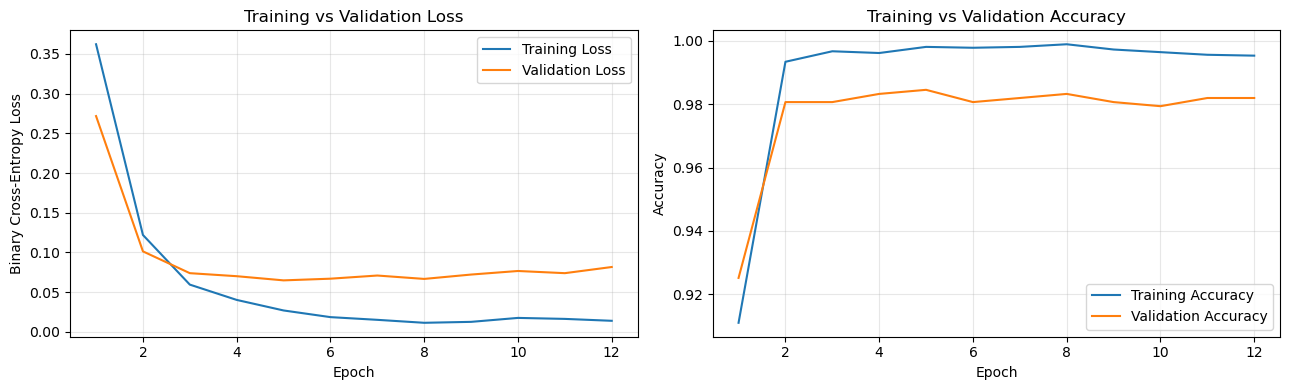

In [14]:

# STEP 4D: Loss and accuracy convergence curves

epochs = range(1, len(history["train_loss"]) + 1)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(epochs, history["train_loss"], label="Training Loss")
axes[0].plot(epochs, history["val_loss"], label="Validation Loss")
axes[0].set_title("Training vs Validation Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Binary Cross-Entropy Loss")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(epochs, history["train_accuracy"], label="Training Accuracy")
axes[1].plot(epochs, history["val_accuracy"], label="Validation Accuracy")
axes[1].set_title("Training vs Validation Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


TEST SET RESULTS
Accuracy:  0.9871
Precision: 0.9490
Recall:    0.9490
F1-score:  0.9490
ROC-AUC:   0.9841

Classification Report:
              precision    recall  f1-score   support

    Not Spam       0.99      0.99      0.99       678
        Spam       0.95      0.95      0.95        98

    accuracy                           0.99       776
   macro avg       0.97      0.97      0.97       776
weighted avg       0.99      0.99      0.99       776



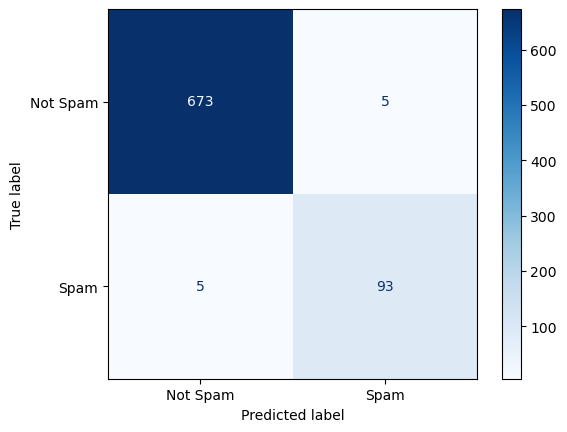

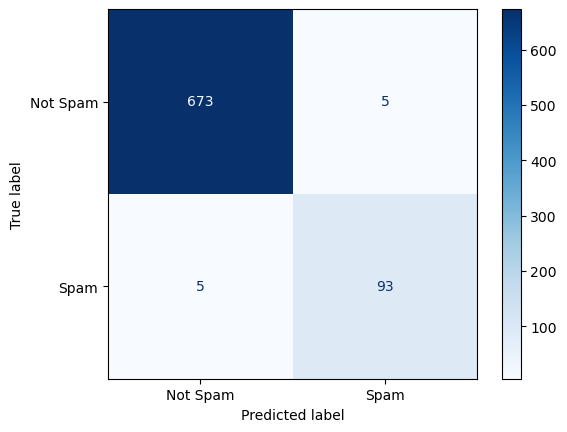

In [15]:

# STEP 5A: Final test-set evaluation

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_auc_score
)

model.eval()

with torch.no_grad():
    test_logits = model(X_test_tensor.to(device))
    test_probabilities = torch.sigmoid(test_logits).cpu().numpy().ravel()

test_predictions = (test_probabilities >= 0.5).astype(int)
y_test_true = y_test_np.astype(int)

print("TEST SET RESULTS")
print("=" * 45)
print(f"Accuracy:  {accuracy_score(y_test_true, test_predictions):.4f}")
print(f"Precision: {precision_score(y_test_true, test_predictions, zero_division=0):.4f}")
print(f"Recall:    {recall_score(y_test_true, test_predictions, zero_division=0):.4f}")
print(f"F1-score:  {f1_score(y_test_true, test_predictions, zero_division=0):.4f}")

if len(np.unique(y_test_true)) == 2:
    print(f"ROC-AUC:   {roc_auc_score(y_test_true, test_probabilities):.4f}")
else:
    print("ROC-AUC: unavailable because the test set contains only one class.")

print("\nClassification Report:")
print(classification_report(
    y_test_true,
    test_predictions,
    labels=[0, 1],
    target_names=["Not Spam", "Spam"],
    zero_division=0
))

cm = confusion_matrix(y_test_true, test_predictions, labels=[0, 1])
display(
    ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Not Spam", "Spam"]
    ).plot(cmap="Blues").figure_
)
plt.show()


In [19]:

# Recreate the prediction function and inference results

import pandas as pd
import torch
import numpy as np

def predict_message(message):
    model.eval()

    # Transform message using the fitted TF-IDF vectorizer
    message_vector = vectorizer.transform([message]).toarray()

    message_tensor = torch.tensor(
        message_vector,
        dtype=torch.float32
    ).to(device)

    with torch.no_grad():
        logits = model(message_tensor)
        spam_probability = torch.sigmoid(logits).item()

    predicted_class = int(spam_probability >= 0.5)

    return {
        "message": message,
        "prediction": "Spam" if predicted_class == 1 else "Not Spam",
        "spam_probability": round(spam_probability, 4),
        "predicted_class_confidence": round(
            spam_probability if predicted_class == 1
            else 1 - spam_probability,
            4
        )
    }


sample_messages = [
    "Congratulations! You have won a free prize. Claim it now!",
    "Hi, are we still meeting for lunch today?",
    "URGENT! You have been selected for a cash reward. Call now!",
    "Please send me the notes after class."
]

inference_results = pd.DataFrame(
    [predict_message(msg) for msg in sample_messages]
)

display(inference_results)


,message,prediction,spam_probability,predicted_class_confidence
0,Congratulations! You have won a free prize. Cl...,Spam,0.9886,0.9886
1,"Hi, are we still meeting for lunch today?",Not Spam,0.0105,0.9895
2,URGENT! You have been selected for a cash rewa...,Spam,0.9818,0.9818
3,Please send me the notes after class.,Not Spam,0.0104,0.9896


In [16]:

# STEP 5C: Save artifacts

import joblib
import json
from pathlib import Path

project_root = Path.cwd()

# If running from the notebook directory, move one level up
if project_root.name == "05_Deep_Learning_NLP":
    project_root = project_root.parent

model_dir = project_root / "models"
report_dir = project_root / "reports"
notebook_dir = project_root / "05_Deep_Learning_NLP"

model_dir.mkdir(parents=True, exist_ok=True)
report_dir.mkdir(parents=True, exist_ok=True)
notebook_dir.mkdir(parents=True, exist_ok=True)

# Save model weights and architecture settings
torch.save(
    {
        "model_state_dict": model.state_dict(),
        "input_dim": X_train_tensor.shape[1],
        "threshold": 0.5
    },
    model_dir / "task05_spam_classifier.pth"
)

# Save fitted TF-IDF vectorizer
joblib.dump(
    vectorizer,
    model_dir / "task05_tfidf_vectorizer.joblib"
)

# Save final test metrics
test_metrics = {
    "accuracy": float(accuracy_score(y_test_true, test_predictions)),
    "precision": float(precision_score(
        y_test_true, test_predictions, zero_division=0
    )),
    "recall": float(recall_score(
        y_test_true, test_predictions, zero_division=0
    )),
    "f1_score": float(f1_score(
        y_test_true, test_predictions, zero_division=0
    ))
}

if len(np.unique(y_test_true)) == 2:
    test_metrics["roc_auc"] = float(
        roc_auc_score(y_test_true, test_probabilities)
    )

with open(report_dir / "task05_test_metrics.json", "w") as f:
    json.dump(test_metrics, f, indent=4)

inference_results.to_csv(
    report_dir / "task05_sample_predictions.csv",
    index=False
)

# Save training history
pd.DataFrame(history).to_csv(
    report_dir / "task05_training_history.csv",
    index=False
)

print("Saved artifacts:")
print(model_dir / "task05_spam_classifier.pth")
print(model_dir / "task05_tfidf_vectorizer.joblib")
print(report_dir / "task05_test_metrics.json")
print(report_dir / "task05_sample_predictions.csv")
print(report_dir / "task05_training_history.csv")


NameError: name 'inference_results' is not defined

In [20]:

# Save sample predictions safely, even if inference_results was not created

sample_messages = [
    "Congratulations! You have won a free prize. Claim it now!",
    "Hi, are we still meeting for lunch today?",
    "URGENT! You have been selected for a cash reward. Call now!",
    "Please send me the notes after class."
]

def predict_message(message):
    model.eval()

    message_vector = vectorizer.transform([message]).toarray()
    message_tensor = torch.tensor(
        message_vector, dtype=torch.float32
    ).to(device)

    with torch.no_grad():
        probability = torch.sigmoid(model(message_tensor)).item()

    prediction = int(probability >= 0.5)

    return {
        "message": message,
        "prediction": "Spam" if prediction == 1 else "Not Spam",
        "spam_probability": round(probability, 4),
        "predicted_class_confidence": round(
            probability if prediction == 1 else 1 - probability, 4
        )
    }

inference_results = pd.DataFrame(
    [predict_message(message) for message in sample_messages]
)

inference_results.to_csv(
    report_dir / "task05_sample_predictions.csv",
    index=False
)

display(inference_results)
print("Sample predictions saved successfully.")


,message,prediction,spam_probability,predicted_class_confidence
0,Congratulations! You have won a free prize. Cl...,Spam,0.9886,0.9886
1,"Hi, are we still meeting for lunch today?",Not Spam,0.0105,0.9895
2,URGENT! You have been selected for a cash rewa...,Spam,0.9818,0.9818
3,Please send me the notes after class.,Not Spam,0.0104,0.9896


Sample predictions saved successfully.


In [21]:

# Save trained model and vectorizer

import torch
import joblib
import json
import pandas as pd
import numpy as np
from pathlib import Path

# Ensure output folders exist
model_dir = Path("models")
report_dir = Path("reports")

model_dir.mkdir(parents=True, exist_ok=True)
report_dir.mkdir(parents=True, exist_ok=True)

# Save model architecture settings and trained weights
torch.save(
    {
        "model_state_dict": model.state_dict(),
        "input_dim": X_train_tensor.shape[1],
        "threshold": 0.5
    },
    model_dir / "task05_spam_classifier.pth"
)

# Save fitted TF-IDF vectorizer
joblib.dump(
    vectorizer,
    model_dir / "task05_tfidf_vectorizer.joblib"
)

print("Model and TF-IDF vectorizer saved successfully.")
print("Model:", model_dir / "task05_spam_classifier.pth")
print("Vectorizer:", model_dir / "task05_tfidf_vectorizer.joblib")


Model and TF-IDF vectorizer saved successfully.
Model: models\task05_spam_classifier.pth
Vectorizer: models\task05_tfidf_vectorizer.joblib


In [22]:

# Save test evaluation metrics

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

test_metrics = {
    "accuracy": float(
        accuracy_score(y_test_true, test_predictions)
    ),
    "precision": float(
        precision_score(y_test_true, test_predictions, zero_division=0)
    ),
    "recall": float(
        recall_score(y_test_true, test_predictions, zero_division=0)
    ),
    "f1_score": float(
        f1_score(y_test_true, test_predictions, zero_division=0)
    )
}

if len(np.unique(y_test_true)) == 2:
    test_metrics["roc_auc"] = float(
        roc_auc_score(y_test_true, test_probabilities)
    )

with open(report_dir / "task05_test_metrics.json", "w") as f:
    json.dump(test_metrics, f, indent=4)

display(pd.DataFrame([test_metrics]))
print("Test metrics saved successfully.")


,accuracy,precision,recall,f1_score,roc_auc
0,0.987113,0.94898,0.94898,0.94898,0.984122


Test metrics saved successfully.


In [23]:

# Save training and validation history

history_df = pd.DataFrame(history)

history_path = report_dir / "task05_training_history.csv"
history_df.to_csv(history_path, index=False)

display(history_df.tail())
print("Training history saved to:", history_path)


,train_loss,val_loss,train_accuracy,val_accuracy
7,0.011448,0.066709,0.998894,0.983226
8,0.012631,0.072203,0.997236,0.980645
9,0.017601,0.076692,0.996407,0.979355
10,0.016357,0.073950,0.995578,0.981935
11,0.013961,0.081701,0.995301,0.981935


Training history saved to: reports\task05_training_history.csv


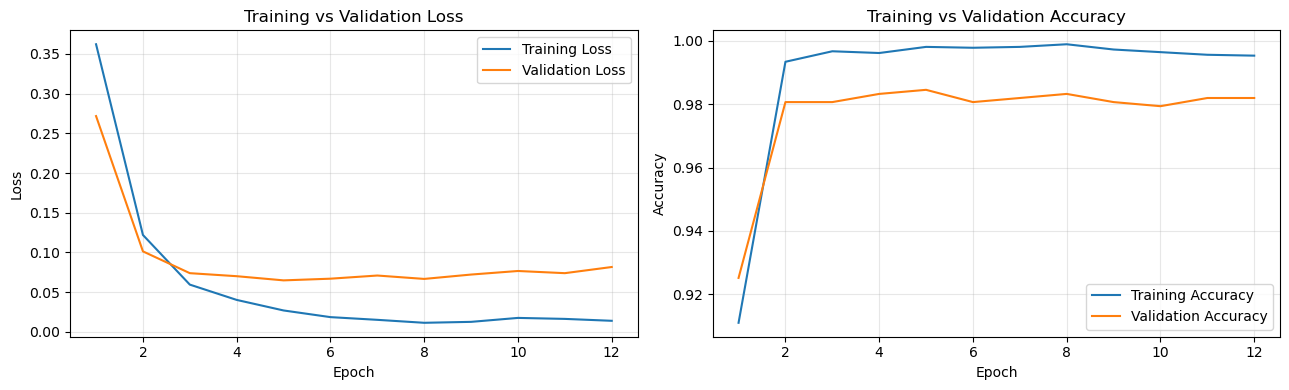

Training curves saved to: reports\task05_training_curves.png


In [24]:

# Plot training and validation curves

import matplotlib.pyplot as plt

epochs = range(1, len(history["train_loss"]) + 1)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

# Loss curves
axes[0].plot(epochs, history["train_loss"], label="Training Loss")
axes[0].plot(epochs, history["val_loss"], label="Validation Loss")
axes[0].set_title("Training vs Validation Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Accuracy curves
axes[1].plot(
    epochs, history["train_accuracy"], label="Training Accuracy"
)
axes[1].plot(
    epochs, history["val_accuracy"], label="Validation Accuracy"
)
axes[1].set_title("Training vs Validation Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()

curves_path = report_dir / "task05_training_curves.png"
plt.savefig(curves_path, dpi=150, bbox_inches="tight")
plt.show()

print("Training curves saved to:", curves_path)


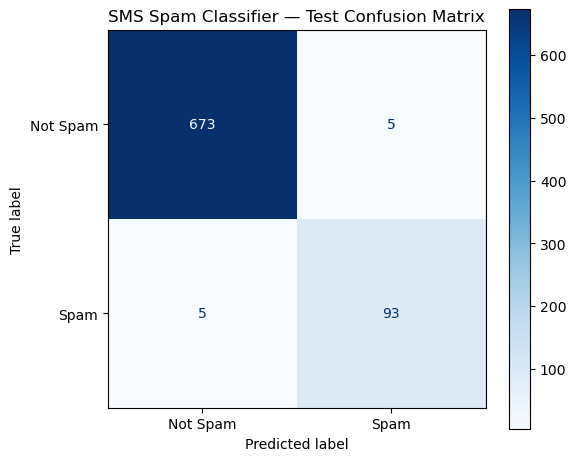

Confusion matrix saved to: reports\task05_confusion_matrix.png


In [25]:

# Save confusion matrix visualization

from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

cm = confusion_matrix(
    y_test_true,
    test_predictions,
    labels=[0, 1]
)

fig, ax = plt.subplots(figsize=(6, 5))

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Not Spam", "Spam"]
).plot(ax=ax, cmap="Blues", values_format="d")

ax.set_title("SMS Spam Classifier — Test Confusion Matrix")
plt.tight_layout()

cm_path = report_dir / "task05_confusion_matrix.png"
plt.savefig(cm_path, dpi=150, bbox_inches="tight")
plt.show()

print("Confusion matrix saved to:", cm_path)


In [26]:

# Verify generated artifacts

expected_files = [
    model_dir / "task05_spam_classifier.pth",
    model_dir / "task05_tfidf_vectorizer.joblib",
    report_dir / "task05_test_metrics.json",
    report_dir / "task05_sample_predictions.csv",
    report_dir / "task05_training_history.csv",
    report_dir / "task05_training_curves.png",
    report_dir / "task05_confusion_matrix.png"
]

for file_path in expected_files:
    status = "OK" if file_path.exists() else "MISSING"
    print(f"{status}: {file_path}")

print("\nSample inference results:")
display(inference_results)


OK: models\task05_spam_classifier.pth
OK: models\task05_tfidf_vectorizer.joblib
OK: reports\task05_test_metrics.json
MISSING: reports\task05_sample_predictions.csv
OK: reports\task05_training_history.csv
OK: reports\task05_training_curves.png
OK: reports\task05_confusion_matrix.png

Sample inference results:


,message,prediction,spam_probability,predicted_class_confidence
0,Congratulations! You have won a free prize. Cl...,Spam,0.9886,0.9886
1,"Hi, are we still meeting for lunch today?",Not Spam,0.0105,0.9895
2,URGENT! You have been selected for a cash rewa...,Spam,0.9818,0.9818
3,Please send me the notes after class.,Not Spam,0.0104,0.9896
